# Notebook 4 · Optimización multiobjetivo robusta

En este notebook se mostrará cómo buscar decisiones **robustas**: buenas no para un modelo, sino para la geología y el clima que no conocemos.

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica · UNAM, Instituto de Geología · 24 de noviembre de 2026
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

**Literatura:**

1. Deb, K. y Gupta, H. (2006). Introducing robustness in multi-objective optimization. *Evolutionary Computation*, 14(4), 463–494.
2. Beyer, H.-G. y Sendhoff, B. (2007). Robust optimization: a comprehensive survey. *Computer Methods in Applied Mechanics and Engineering*, 196(33–34), 3190–3218.
3. Rodríguez-Pretelín, A., Nowak, W. y Morales-Casique, E. (2022). Optimization-based clustering of random fields for computationally efficient and goal-oriented uncertainty quantification. *Advances in Water Resources*, 162, 104146.

### Cómo usar este cuaderno

Ejecuta las celdas en orden. Todo corre en unos 4 minutos; las celdas lentas lo dicen. Las marcas ✏️ **Inténtalo** son variaciones opcionales.

| Sección | La pregunta | Qué se hace | Programa |
|---|---|---|---|
| 1 · La robustez con un problema de prueba | ¿qué es una decisión robusta? | dos cimas, Monte Carlo y siete ejemplos de uso | teoría del tema 4 |
| 2 · El frente de 2024 ante la incertidumbre geológica | ¿qué menú de tres objetivos le doy a Fritz? | frentes negro, verde, rojo y azul | práctica 4.1 y 4.2 |
| 3 · Agua contra riesgo | ¿cuánta agua puedo bombear con qué riesgo? | el riesgo como objetivo, validación y la decisión | práctica 4.1 y 4.2 |
| 4 · El costo de la robustez y cómo bajarlo | ¿cuánto cuesta no saber? | geología y clima, medir, OCA | práctica 4.2 |
| 5 · Cierre del curso | | las cuatro sesiones en una tabla | |

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 0 · PREPARACIÓN</p>

## 0 · Preparación (2 min)

Las herramientas, y después los dos **ensambles de geologías** (la segunda celda). La primera vez se fabrican con el simulador (unos 50 segundos) y se
guardan; después se leen del disco.

Importar dependencias:

In [1]:
import sys; sys.path.append('..'); sys.path.append('Información/codigo'); sys.path.append('Información/codigo/pyOMOPSO')
import time
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from scipy.optimize import linprog

import hidra, pso
from ParOMOPSO_det import parOMOPSO_det as parOMOPSO           # el optimizador (en el original: from ParOMOPSO import parOMOPSO)
from Mat_cost import *                                          # mat_cost: los costos del archivo como arreglo

def frente(e_file):
    # el archivo de OMOPSO como dos tablas: F (objetivos) y X (decisiones), una fila por solución
    return np.array([np.ravel(s['cost']) for s in e_file]), np.array([np.ravel(s['position']) for s in e_file])

hidra.verificar_entorno()
S_MAX, S_HUM, DEMANDA = 3.0, 1.25, 1200.0
alpha0, alpha_h0 = hidra.matriz_respuesta(), hidra.coeficientes_humedal()      # el modelo homogéneo de las sesiones 1 a 3

Python 3.11.14 | numpy 2.4.1 | scipy 1.17.0 | matplotlib 3.10.8 | plotly 6.7.0 | otter 7.0.0
Simulador listo: una corrida tarda 0.05 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


### Las realizaciones geológicas

Esta celda genera, con `hidra`, los dos **ensambles de geologías**: uno para **optimizar** y otro, independiente, para **validar**. Cada geología sale de su
propia **semilla**, así que las geologías son siempre las mismas, en cualquier computadora: todos obtenemos los mismos números, en clase y en la tarea.

En clase y en la tarea usamos **200** de cada una. En casa puedes cambiar `N_GEOLOGIAS` y volver a correr el cuaderno para ver qué cambia con más geologías:

- Las primeras 200 siguen siendo las mismas; solo se generan las nuevas (unos 0.13 s por geología y por ensamble) y se guardan para la próxima vez.
- Con más geologías el cuaderno usa más memoria: hasta unas 1 000 corre en una laptop común; con 5 000 necesita unos 2 GB y varios minutos.
- Los números que cita el texto del cuaderno son los de 200.

In [2]:
N_GEOLOGIAS = 200        # geologías de cada ensamble. En clase y en la tarea, 200; en casa puedes subirlo (500, 1000, 5000…)

OPT = hidra.ensamble(N_GEOLOGIAS, "optimizacion")         # para optimizar
VAL = hidra.ensamble(N_GEOLOGIAS, "validacion")           # distintas, para validar
A, H = OPT["alpha"], OPT["alpha_h"]                        # (N, 3, 3) y (N, 3): la matriz de respuesta y la fila del humedal de cada geología
A_val, H_val = VAL["alpha"], VAL["alpha_h"]
print("ensambles listos:", A.shape[0], "geologías para optimizar y", A_val.shape[0], "para validar")

ensambles listos: 200 geologías para optimizar y 200 para validar


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · LA ROBUSTEZ CON UN PROBLEMA DE PRUEBA · TEORÍA DEL TEMA 4</p>

## 1 · La robustez con un problema de prueba (18 min)

**La pregunta:** ¿qué es una decisión robusta?

Antes del acuífero, la idea en una dimensión, donde se ve todo. Una función con **dos cimas**:

$$
f(x) = \exp\!\left[-\left(\frac{x - 2}{0.3}\right)^2\right] + 0.8\,\exp\!\left[-\left(\frac{x - 7}{1.5}\right)^2\right], \qquad 0 \le x \le 10
$$

La cima en $x = 2$ es **alta y angosta** ($f = 1$); la de $x = 7$ es **baja y ancha** ($f = 0.8$). Sin incertidumbre, el máximo es $x = 2$.

Ahora la incertidumbre: lo que decidimos no es exactamente lo que ocurre. Decidimos $x$, pero el sistema responde a $x + \delta$, con $\delta$ al azar,
$\delta \sim \mathcal{N}(0,\ \sigma = 0.5)$. En el acuífero, $\delta$ será la geología que no conocemos.

### 1.1 Definición de la función objetivo

In [3]:
# Función objetivo de muestra: dos cimas
def f(x):
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - 2) / 0.3)**2) + 0.8 * np.exp(-((x - 7) / 1.5)**2)

SIGMA = 0.5                                        # la incertidumbre: desviación de δ
rng = np.random.default_rng(0)
DELTAS = rng.normal(0, SIGMA, 2000)                # 2 000 muestras de δ: la incertidumbre escrita como números
xs = np.linspace(0, 10, 501)
print(f"f(2) = {f(2):.3f}   f(7) = {f(7):.3f}")

f(2) = 1.000   f(7) = 0.800


### 1.2 El problema determinista, con PSO

El mismo `pso.PSO` de la sesión 2, maximizando ($\text{MinProblem} = 0$) con una variable. (Con la semilla 0 el enjambre se queda en la cima ancha:
una cima angosta es difícil de encontrar. Como en la sesión 2, una corrida no es un resultado.)

In [4]:
# Definir el problema de optimización
problem = {
        'CostFunction': lambda x: f(x[0]),
        'nVar': 1,
        'VarMin': 0,
        'VarMax': 10,
        'MinProblem': 0,
    }
np.random.seed(1)
gbest_det, _ = pso.PSO(problem, MaxIter=60, PopSize=20, c1=1.5, c2=2, w=1, wdamp=0.95, verbose=False)
print(f"óptimo determinista: x = {gbest_det['position'][0]:.3f}, f = {gbest_det['cost']:.3f}")

óptimo determinista: x = 2.000, f = 1.000


### 1.3 Monte Carlo paso a paso

¿Qué tan buena es una decisión $x$ si lo que ocurre es $x + \delta$? Lo que se **espera** obtener es el valor esperado

$$
E\big[f(x + \delta)\big] = \int f(x + \delta)\, p(\delta)\, d\delta \;\approx\; \frac{1}{N}\sum_{k=1}^{N} f(x + \delta_k)
$$

**Monte Carlo** cambia la integral por un promedio sobre N muestras de la incertidumbre. Es todo lo que hace falta para «robustecer» cualquier función objetivo.

x = 2.0: f(x) = 1.000 sin incertidumbre, E[f(x + δ)] = 0.387 con incertidumbre
x = 7.0: f(x) = 0.800 sin incertidumbre, E[f(x + δ)] = 0.724 con incertidumbre


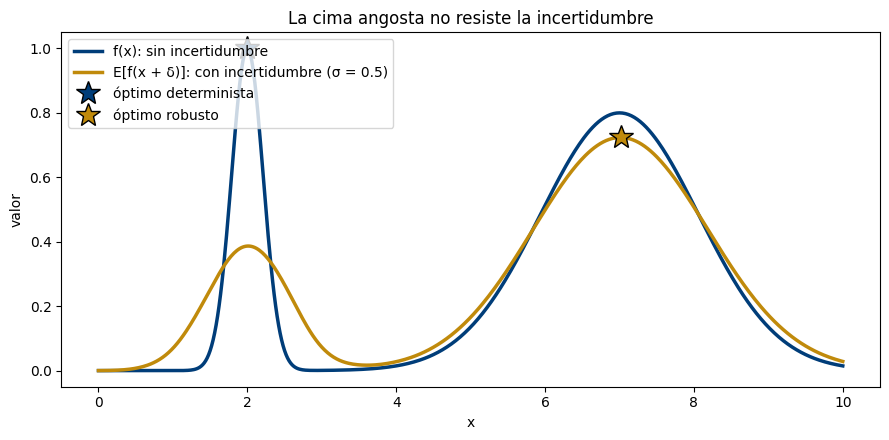

In [5]:
def esperanza(x, deltas=DELTAS):
    # 1.- evaluar la función en cada muestra de la incertidumbre
    valores = f(x + deltas)
    # 2.- promediar: el valor esperado
    return valores.mean()

for x in (2.0, 7.0):
    print(f"x = {x}: f(x) = {f(x):.3f} sin incertidumbre, E[f(x + δ)] = {esperanza(x):.3f} con incertidumbre")

E_x = np.array([esperanza(x) for x in xs])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(xs, f(xs), color='#003D79', lw=2.5, label='f(x): sin incertidumbre')
ax.plot(xs, E_x, color='#C08A0B', lw=2.5, label='E[f(x + δ)]: con incertidumbre (σ = 0.5)')
ax.plot(2, f(2), '*', ms=18, mfc='#003D79', mec='k', label='óptimo determinista')
ax.plot(xs[np.argmax(E_x)], E_x.max(), '*', ms=18, mfc='#C08A0B', mec='k', label='óptimo robusto')
ax.set_xlabel('x'); ax.set_ylabel('valor'); ax.legend(); ax.set_title('La cima angosta no resiste la incertidumbre')
plt.tight_layout(); plt.show()

Con incertidumbre, la cima angosta se derrumba: casi siempre se cae por un lado. La ancha **resiste**. Eso es una solución robusta.

**Definición (robustez de tipo I, Deb y Gupta, 2006).** Una solución robusta es la óptima de la **función efectiva**: el valor esperado de la función objetivo
cuando la decisión o los parámetros se perturban dentro de su incertidumbre,

$$
f^{	ext{ef}}(x) = E_\deltaig[f(x + \delta)ig], \qquad x^{	ext{rob}} = rg\max_x f^{	ext{ef}}(x).
$$

En el acuífero, $\delta$ es la geología: la función efectiva es el promedio de los objetivos sobre el ensamble (sección 2). Con varios objetivos, el frente
robusto es el frente de las funciones efectivas.

### 1.4 Ejemplos de uso

Siete ejemplos cortos para aprender a **usar** la robustez: qué se calcula, qué se elige y qué esperar.

#### Ejemplo 1 · ¿Cuántas muestras? El error de Monte Carlo

La estimación con N muestras tiene un error que baja como $1/\sqrt{N}$: para la mitad de error hacen falta **cuatro veces** más muestras.

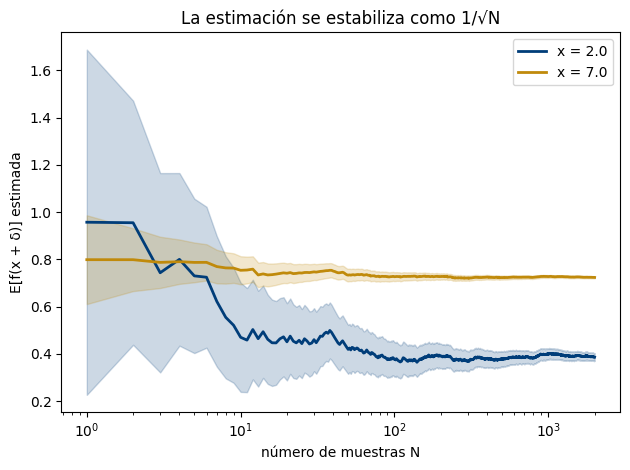

In [6]:
N = np.arange(1, 2001)
for x, c in ((2.0, '#003D79'), (7.0, '#C08A0B')):
    v = f(x + DELTAS)
    media_acum = np.cumsum(v) / N
    error = v.std() / np.sqrt(N)
    plt.fill_between(N, media_acum - 2 * error, media_acum + 2 * error, color=c, alpha=0.2)
    plt.plot(N, media_acum, color=c, lw=2, label=f'x = {x}')
plt.xscale('log'); plt.xlabel('número de muestras N'); plt.ylabel('E[f(x + δ)] estimada'); plt.legend()
plt.title('La estimación se estabiliza como 1/√N'); plt.tight_layout(); plt.show()

#### Ejemplo 2 · Tres medidas de robustez, dos respuestas

«Robusto» no es una sola cosa. Depende de lo que se pregunte:

| Medida | Pregunta | Fórmula |
|---|---|---|
| media | ¿cuánto espero obtener? | $E[f(x + \delta)]$ |
| peor caso | ¿cuánto obtengo en el 5 % de los casos malos? | percentil 5 de $f(x + \delta)$ |
| fiabilidad | ¿qué tan seguido paso de un umbral $u$? | $P\big(f(x + \delta) > u\big)$ |

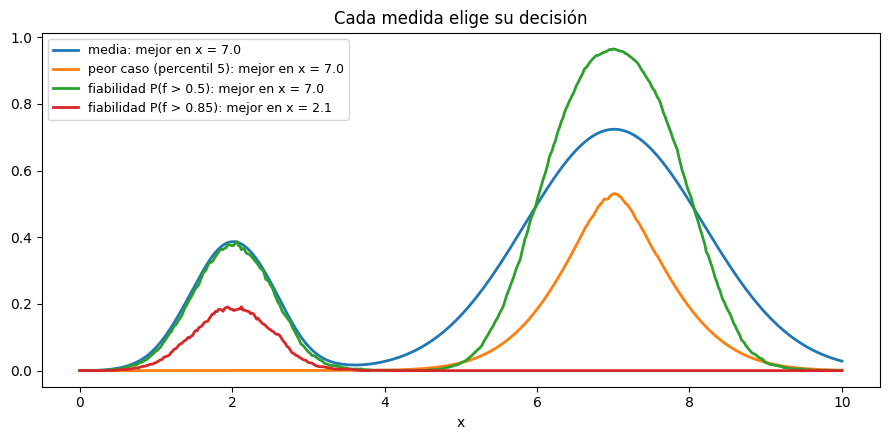

In [7]:
valores = f(xs[:, None] + DELTAS[None, :])                 # (501 decisiones, 2000 muestras)
medidas = {'media': valores.mean(axis=1), 'peor caso (percentil 5)': np.percentile(valores, 5, axis=1),
           'fiabilidad P(f > 0.5)': (valores > 0.5).mean(axis=1), 'fiabilidad P(f > 0.85)': (valores > 0.85).mean(axis=1)}
fig, ax = plt.subplots(figsize=(9, 4.5))
for nombre, m in medidas.items():
    ax.plot(xs, m, lw=2, label=f'{nombre}: mejor en x = {xs[np.argmax(m)]:.1f}')
ax.set_xlabel('x'); ax.legend(fontsize=9); ax.set_title('Cada medida elige su decisión')
plt.tight_layout(); plt.show()

La media, el peor caso y la fiabilidad con umbral 0.5 eligen la cima ancha. Pero si la pregunta es «¿qué tan seguido paso de 0.85?», la cima ancha **nunca**
llega (vale 0.8) y gana la angosta. La medida de robustez es una decisión, como los pesos de la sesión 3.

#### Ejemplo 3 · PSO sobre la esperanza

Para robustecer el problema basta cambiar la función objetivo por su esperanza. El optimizador es el mismo.

In [8]:
MUESTRAS = DELTAS[:200]                                    # 200 muestras, las mismas para todas las partículas
problema_robusto = dict(problem, CostFunction=lambda x: f(x[0] + MUESTRAS).mean())
np.random.seed(0)
gbest_rob, _ = pso.PSO(problema_robusto, MaxIter=60, PopSize=20, c1=1.5, c2=2, w=1, wdamp=0.95, verbose=False)
print(f"óptimo determinista: x = {gbest_det['position'][0]:.2f} | óptimo robusto: x = {gbest_rob['position'][0]:.2f}, E[f] = {gbest_rob['cost']:.3f}")

óptimo determinista: x = 2.00 | óptimo robusto: x = 6.98, E[f] = 0.728


#### Ejemplo 4 · OMOPSO: lo que cuesta contra lo que se espera

Supongamos que decidir $x$ cuesta $x$ (como bombear: más es más caro). Con dos objetivos, **el costo** y **lo que se espera obtener**, OMOPSO da el menú robusto.
Es el mismo esquema que usaremos en el acuífero (sección 3): agua contra riesgo. OMOPSO minimiza y pide objetivos positivos: usamos $x + 0.01$ y $1.5 - E[f]$.

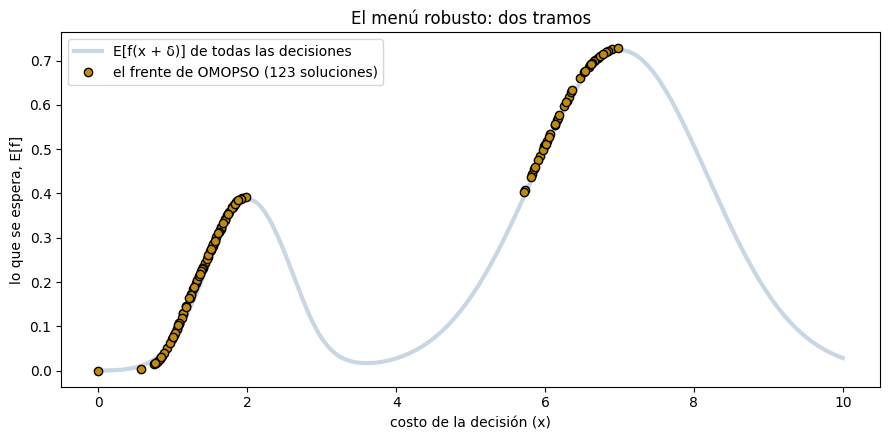

In [9]:
def costo_y_esperanza(x):
    return np.array([[x[0] + 0.01, 1.5 - f(x[0] + MUESTRAS).mean()]]).T      # una columna: [costo, 1.5 − E[f]]

OMOPSO = {'MaxIter': 60, 'nPop': 30, 'w1': 0.1, 'w2': 0.5, 'e': 0.001, 'c1': 1.5, 'c2': 2, 'nGrid': 7, 'alpha': 0.1,
          'wdamp': 0.99, 'r1': 0, 'r2': 1, 'verbose': 0}
np.random.seed(1)
e_ce, _, _ = parOMOPSO({'CostFunction': costo_y_esperanza, 'nVar': 1, 'VarMin': 0, 'VarMax': 10}, OMOPSO)
F_ce, X_ce = frente(e_ce)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(xs, E_x, color='#c9d6e4', lw=3, label='E[f(x + δ)] de todas las decisiones')
ax.plot(X_ce[:, 0], 1.5 - F_ce[:, 1], 'o', mfc='#C08A0B', mec='k', ms=6, label=f'el frente de OMOPSO ({len(F_ce)} soluciones)')
ax.set_xlabel('costo de la decisión (x)'); ax.set_ylabel('lo que se espera, E[f]'); ax.legend(loc='upper left')
ax.set_title('El menú robusto: dos tramos'); plt.tight_layout(); plt.show()

El frente tiene **dos tramos**. El primero sube hasta la cima angosta: la opción **barata**, con poco que esperar. El segundo empieza cuando la cima ancha supera lo
que daba la angosta y sube hasta $x = 7$: la opción **cara** y robusta. Entre los dos hay un salto: ninguna decisión intermedia vale la pena. Elegir es, otra vez, de
las personas.

#### Ejemplo 5 · Las mismas muestras para todas las partículas

Si cada evaluación usa muestras **nuevas**, la función objetivo tiene ruido: la misma $x$ da números distintos y el enjambre persigue golpes de suerte. Con muestras
**comunes** (las mismas para todos) las comparaciones son justas.

In [10]:
def esperanza_ruidosa(x, n=10):
    return f(x[0] + np.random.normal(0, SIGMA, n)).mean()      # muestras nuevas en cada evaluación

resultados = {}
for nombre, func in (('muestras nuevas (10 por evaluación)', esperanza_ruidosa), ('muestras comunes (las mismas 10)', lambda x: f(x[0] + DELTAS[:10]).mean())):
    xs_fin = []
    for semilla in range(10):
        np.random.seed(semilla)
        g, _ = pso.PSO(dict(problem, CostFunction=func), MaxIter=60, PopSize=20, c1=1.5, c2=2, w=1, wdamp=0.95, verbose=False)
        xs_fin.append((g['position'][0], g['cost'], esperanza(g['position'][0])))
    resultados[nombre] = np.array(xs_fin)
    r = resultados[nombre]
    print(f"{nombre:38s}: x de {r[:, 0].min():.2f} a {r[:, 0].max():.2f} | prometido {r[:, 1].mean():.3f} | real {r[:, 2].mean():.3f}")

muestras nuevas (10 por evaluación)   : x de 6.69 a 7.37 | prometido 0.785 | real 0.714
muestras comunes (las mismas 10)      : x de 6.95 a 6.95 | prometido 0.754 | real 0.723


Con muestras nuevas el enjambre se queda con la evaluación más afortunada y **promete** más de lo que da. Con muestras comunes todas las semillas llegan al mismo
lugar. En el acuífero, las muestras comunes son el **mismo ensamble de geologías** para todas las decisiones.

#### Ejemplo 6 · La maldición del optimizador

Aun con muestras comunes, si son **pocas** el optimizador encuentra la decisión que mejor esquiva **esas** muestras. Lo prometido (con las N muestras) es más que lo
real (con 2 000 nuevas). Hay que **validar** fuera de la muestra.

In [11]:
print("  N    prometido   real (2 000 muestras)")
for n in (3, 5, 10, 50, 500):
    prometido, real = [], []
    for s in range(20):
        Dn = np.random.default_rng(100 + s).normal(0, SIGMA, n)
        m = f(xs[:, None] + Dn[None, :]).mean(axis=1); k = np.argmax(m)
        prometido.append(m[k]); real.append(E_x[k])
    print(f"{n:4d}     {np.mean(prometido):.3f}      {np.mean(real):.3f}")

  N    prometido   real (2 000 muestras)
   3     0.748      0.677
   5     0.727      0.716
  10     0.726      0.714
  50     0.723      0.723
 500     0.723      0.724


#### Ejemplo 7 · El costo de la robustez, en miniatura

Mientras más incertidumbre, menos se puede esperar. La diferencia entre lo que promete el óptimo determinista ($f = 1$) y lo que da el óptimo robusto es el
**costo de la robustez**. En la sección 4 lo mediremos en el acuífero, en metros cúbicos.

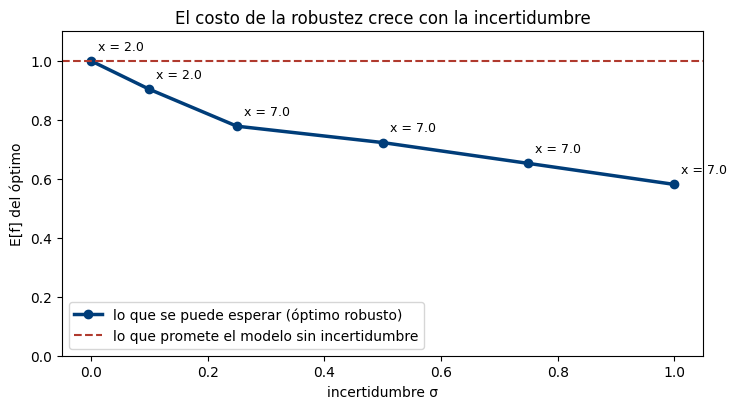

In [12]:
sigmas = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
E_rob, x_rob = [], []
for s in sigmas:
    d = np.random.default_rng(1).normal(0, s, 2000) if s > 0 else np.zeros(1)
    m = f(xs[:, None] + d[None, :]).mean(axis=1); E_rob.append(m.max()); x_rob.append(xs[np.argmax(m)])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sigmas, E_rob, 'o-', color='#003D79', lw=2.5, label='lo que se puede esperar (óptimo robusto)')
ax.axhline(1, color='#B03A2E', ls='--', label='lo que promete el modelo sin incertidumbre')
for s, e, x in zip(sigmas, E_rob, x_rob):
    ax.annotate(f'x = {x:.1f}', (s, e), xytext=(5, 8), textcoords='offset points', fontsize=9)
ax.set_xlabel('incertidumbre σ'); ax.set_ylabel('E[f] del óptimo'); ax.set_ylim(0, 1.1); ax.legend()
ax.set_title('El costo de la robustez crece con la incertidumbre'); plt.tight_layout(); plt.show()

✏️ **Inténtalo:** cambia `SIGMA` a 0.1 y vuelve a correr la sección. ¿Cuál cima gana ahora?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · EL FRENTE DE 2024 ANTE LA INCERTIDUMBRE GEOLÓGICA · PRÁCTICA 4.1 Y 4.2</p>

## 2 · El frente de 2024 ante la incertidumbre geológica (22 min)

**La pregunta de Fritz:** ¿qué menú de tres objetivos le doy si no conozco la geología?

Es el problema de la sesión 3 (sección 3): tres objetivos y el humedal como restricción. Cuatro frentes, uno tras otro:

| Frente | Qué es |
|---|---|
| **negro** | el frente determinista de la sesión 3, con el acuífero homogéneo |
| **verde** | esas mismas decisiones evaluadas en las geologías y **promediadas**: el impacto de la incertidumbre geológica |
| **rojo** | el frente robusto: cada esquema de bombeo evaluado en todas las geologías; el frente son los **no dominados de los promedios** |
| **azul** | el frente rojo, exigiendo además **fiabilidad**: que la decisión cumpla las reglas en al menos el 90 % de las geologías |

El cuaderno original perturbaba la matriz $\alpha$ con ruido gaussiano para fabricar 10 «realizaciones»; aquí usamos las 200 **geologías** del ensamble: cada una es un
campo de conductividad con su propia matriz.

### 2.1 El problema y el frente determinista (negro)

$$
\min_{\mathbf{p}}\; \big(\, S(\mathbf{p}),\ \text{Costo}(\mathbf{p}),\ I(\mathbf{p}) \,\big), \qquad
S = \sum_{i=1}^{3} s_i, \quad
\text{Costo} = \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i\big), \quad
I = \sum_{i=1}^{3} \exp\bigl(-k\,[c_i^0 + a_i\,p_i]\bigr)
$$

sujeto a $s_i \le 3$ m, $s_h \le 1.25$ m y $0 \le p_i \le 500$ m³/d, con $s_i = \sum_j \alpha_{ij} p_j$. **La geología entra por $\alpha$**: con otra geología,
las mismas decisiones abaten, cuestan y castigan distinto.

In [13]:
C_QP = np.array([0.01, 0.015, 0.02]); GSLEV = np.array([40.0, 40.0, 40.0]); H0 = np.array([34.0, 34.0, 15.0])
C_BASE = np.array([2.0, 1.5, 0.8]); A_IDX = np.array([0.10, 0.20, 0.15]) / 10; K_IDX = 0.5

def Robust_analysis(x, K_alpha, K_alpha_h, M=0.0):
    # Los tres objetivos de la decisión x con la geología (K_alpha, K_alpha_h). Con M > 0, el castigo graduado de la sesión 3
    s_sim = K_alpha @ x                                                  # abatimiento en los tres pozos
    s_hum = K_alpha_h @ x                                                # abatimiento en el humedal
    v = np.maximum(s_sim - S_MAX, 0).sum() + max(s_hum - S_HUM, 0)       # cuánto se rompen las reglas
    return np.array([s_sim.sum() + M * v,
                     np.sum(C_QP * x * (GSLEV - H0 + s_sim)) + M * v,
                     np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * x))) + M * v])

# Función objetivo de muestra: el modelo homogéneo de las sesiones 1 a 3
def GW_Problem(x):
    return Robust_analysis(np.asarray(x, dtype=float), alpha0, alpha_h0, M=10.0)[:, None]

problem = {
        'CostFunction': GW_Problem,
        'nVar': 3,
        'VarMin': 0,
        'VarMax': 500,
    }

# Running par_OMOPSO (esta celda tarda unos 20 segundos)
print('Running parOMOPSO ...')
np.random.seed(42); t0 = time.time()
e_file, rep, rep_time = parOMOPSO(problem, dict(OMOPSO, MaxIter=100))
print(len(e_file), f"soluciones en el frente determinista ({time.time() - t0:.0f} s)")

Running parOMOPSO ...


216 soluciones en el frente determinista (19 s)


### 2.2 El impacto de la incertidumbre geológica (verde)

#### Las realizaciones

Las 200 geologías del ensamble; aquí, las diez primeras:

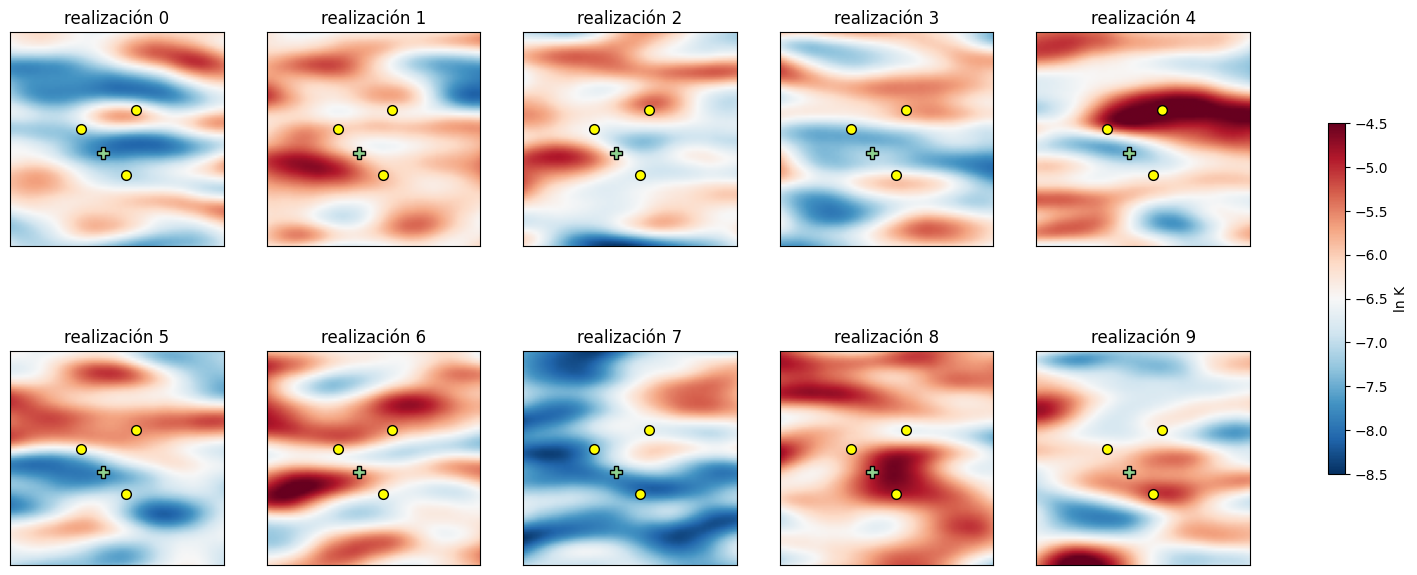

In [14]:
num_realizaciones = len(A)
simulaciones = {"alpha": A, "alpha_h": H}

fig, ejes = plt.subplots(2, 5, figsize=(20, 7.6))
for k, ax in enumerate(ejes.ravel()):
    im = ax.imshow(OPT["logK"][k], origin="lower", extent=[0, hidra.LADO, 0, hidra.LADO], cmap="RdBu_r", vmin=-8.5, vmax=-4.5)
    for (x, y) in hidra.pozos_xy():
        ax.plot(x, y, "o", ms=7, mfc="yellow", mec="k")
    ax.plot(*hidra.humedal_xy(), "P", ms=9, mfc="#8fd18f", mec="k")
    ax.set_title(f"realización {k}"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=ejes, label="ln K", shrink=0.6)
plt.show()

#### Evaluación de las realizaciones espaciales a través de la función de objetivos

Cada decisión del frente determinista se evalúa en cada geología y sus objetivos se **promedian** (las celdas del original):

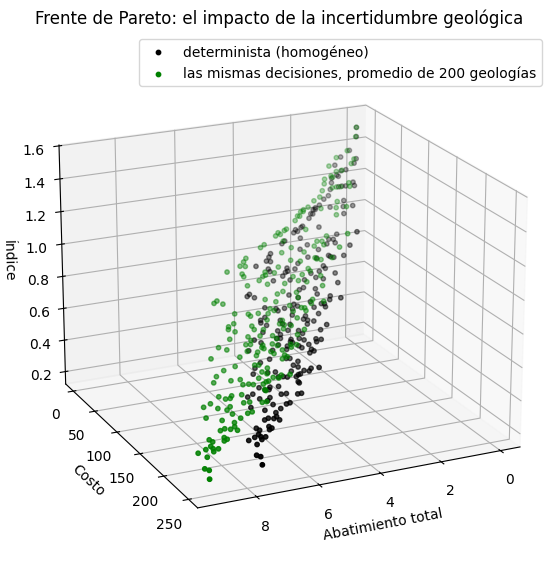

In [15]:
# Obtener los valores de bombeo del frente de Pareto determinista
pumping = []
for i in range(len(e_file)):
    pumping.append(np.ravel(e_file[i]['position']))

# Robust matriz
Het_mat = []
for i in range(0, len(pumping)):
    # Seleccionas un valor de bombeo
    x = pumping[i]
    y_mat = []
    for j in range(0, num_realizaciones):
        y = Robust_analysis(x, simulaciones["alpha"][j], simulaciones["alpha_h"][j])
        y_mat.append(y)
    # Calcular el promedio a lo largo de las realizaciones
    promedio_y = np.mean(np.array(y_mat), axis=0)
    Het_mat.append(promedio_y)
Het_mat = np.array(Het_mat)

det = np.array([Robust_analysis(x, alpha0, alpha_h0) for x in pumping])      # el negro, sin castigo
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection="3d")
ax.scatter3D(det[:, 0], det[:, 1], det[:, 2], color="black", s=10, label="determinista (homogéneo)")
ax.scatter3D(Het_mat[:, 0], Het_mat[:, 1], Het_mat[:, 2], color="green", s=10, label="las mismas decisiones, promedio de 200 geologías")
ax.set_xlabel("Abatimiento total"); ax.set_ylabel("Costo"); ax.set_zlabel("Índice"); ax.legend()
ax.view_init(elev=20, azim=65); plt.title("Frente de Pareto: el impacto de la incertidumbre geológica"); plt.show()

# La misma figura, interactiva: arrastra para girar, rueda para acercar, doble clic para volver a la vista inicial
fig = hidra.frente_3d((det, "determinista (homogéneo)", "black"),
                      (Het_mat, "las mismas decisiones, promedio de 200 geologías", "green"),
                      ejes=("Abatimiento total", "Costo", "Índice"), titulo="Frente de Pareto: el impacto de la incertidumbre geológica")
fig.show()

#### Las caras del frente

Un frente de tres objetivos se lee mejor por sus **caras**: los tres pares de objetivos en 2-D. Cada cara es lo que se ve al mirar la figura 3-D de frente,
desde un lado y desde arriba.

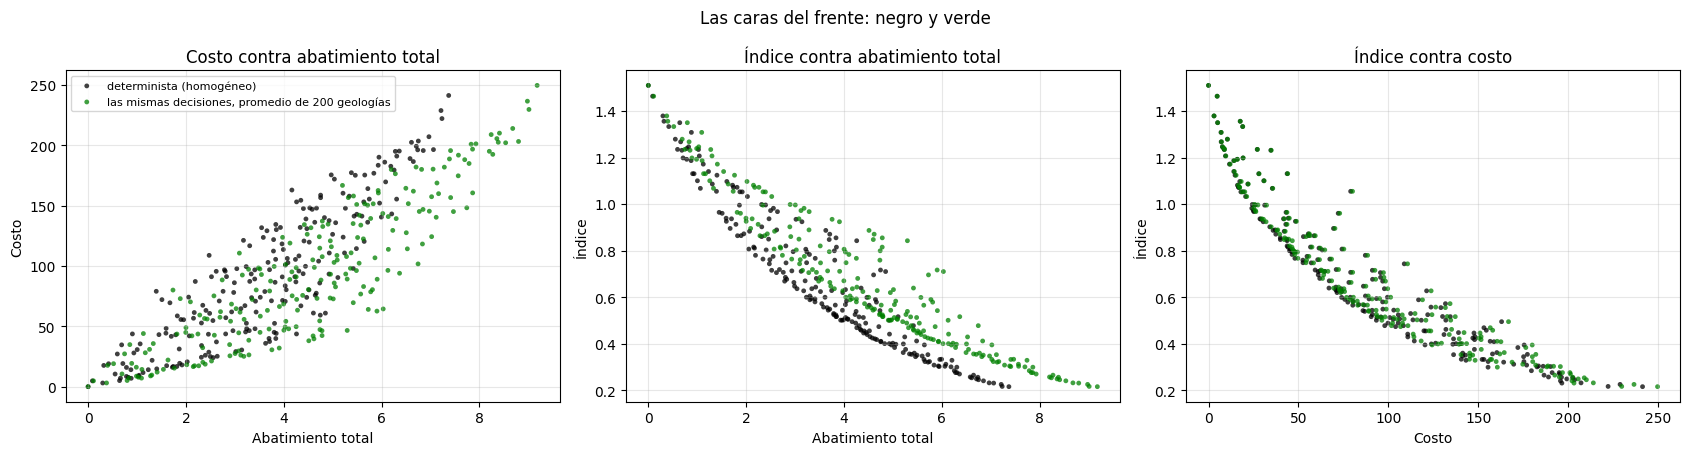

In [16]:
hidra.caras_frente((det, "determinista (homogéneo)", "black"), (Het_mat, "las mismas decisiones, promedio de 200 geologías", "green"),
                   ejes=("Abatimiento total", "Costo", "Índice"), titulo="Las caras del frente: negro y verde")
plt.show()

En promedio, las mismas decisiones **abaten más** de lo que prometía el homogéneo (alrededor de 25 % más): en las caras, el verde se corre hacia la derecha en
el abatimiento. El costo apenas cambia (unos 3 %): lo domina la altura fija hasta el nivel estático, no el abatimiento. El índice no cambia: no depende de la geología.

### 2.3 El frente robusto (rojo)

Ahora no se evalúa un frente ya hecho: se **optimiza** directamente con los promedios. Cada esquema de bombeo se evalúa en las 200 geologías, se promedian sus
objetivos, y OMOPSO busca los **no dominados de los promedios**:

$$
\min_{\mathbf{p}}\; \Big(\, E\big[S(\mathbf{p})\big],\ E\big[\text{Costo}(\mathbf{p})\big],\ I(\mathbf{p}) \,\Big) \qquad \text{sujeto a} \qquad
E[s_i] \le 3\ \text{m}, \quad E[s_h] \le 1.25\ \text{m}
$$

**donde** $E[\cdot]$ es el promedio sobre las 200 geologías (Monte Carlo, como en la sección 1). Las reglas se exigen **en promedio**. Es la optimización robusta
por valor esperado (Deb y Gupta, 2006).

In [17]:
def GW_Problem_promedio(x, M=10.0):
    # Los tres objetivos de 2024, promediados sobre las 200 geologías; las reglas, en promedio
    x = np.asarray(x, dtype=float)
    s_sim = A @ x                                                          # (N, 3): abatimiento de los pozos en cada geología
    S_esp = s_sim.sum(axis=1).mean()                                       # 1.- abatimiento total esperado
    costo_esp = np.sum(C_QP * x * (GSLEV - H0 + s_sim), axis=1).mean()     # 2.- costo esperado
    I = np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * x)))                      # 3.- índice (no depende de la geología)
    v = np.maximum(s_sim.mean(axis=0) - S_MAX, 0).sum() + max((H @ x).mean() - S_HUM, 0)
    return np.array([[S_esp + M * v, costo_esp + M * v, I + M * v]]).T

# Running par_OMOPSO (unos 20 segundos)
print('Running parOMOPSO con los promedios ...')
np.random.seed(42); t0 = time.time()
e_file_rojo, _, _ = parOMOPSO({'CostFunction': GW_Problem_promedio, 'nVar': 3, 'VarMin': 0, 'VarMax': 500}, dict(OMOPSO, MaxIter=100, nPop=40))
_, X_rojo = frente(e_file_rojo)
print(len(e_file_rojo), f"soluciones en el frente robusto ({time.time() - t0:.0f} s)")

Running parOMOPSO con los promedios ...


240 soluciones en el frente robusto (22 s)


### 2.4 ¿Qué tan seguido fallan?

Los frentes verde y rojo hablan de **promedios**. Pero Fritz vive en una sola geología, la real, y en ella la decisión cumple las reglas o no. Medimos el **riesgo**:
la fracción de geologías en que la decisión rompe alguna regla (algún pozo > 3 m o el humedal > 1.25 m). Para que sea honesto, en las 200 geologías de
**validación**, que ningún optimizador vio.

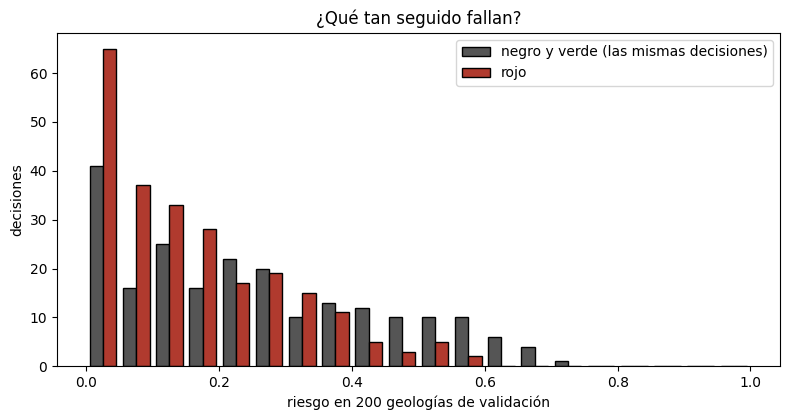

riesgo medio: negro/verde 25% (máximo 72%) | rojo 16% (máximo 56%)


In [18]:
def riesgo(x, A=A, H=H, s_hum=S_HUM):
    # fracción de geologías en que la decisión x rompe alguna regla (algún pozo > 3 m o el humedal > s_hum)
    return np.mean(((A @ x) > S_MAX + 1e-9).any(axis=1) | ((H @ x) > s_hum + 1e-9))

X_negro = np.array(pumping)
r_negro = np.array([riesgo(x, A_val, H_val) for x in X_negro]); r_rojo = np.array([riesgo(x, A_val, H_val) for x in X_rojo])
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.hist([r_negro, r_rojo], bins=np.linspace(0, 1, 21), color=['#555555', '#B03A2E'], label=['negro y verde (las mismas decisiones)', 'rojo'], edgecolor='k')
ax.set_xlabel('riesgo en 200 geologías de validación'); ax.set_ylabel('decisiones'); ax.legend(); ax.set_title('¿Qué tan seguido fallan?')
plt.tight_layout(); plt.show()
print(f"riesgo medio: negro/verde {r_negro.mean():.0%} (máximo {r_negro.max():.0%}) | rojo {r_rojo.mean():.0%} (máximo {r_rojo.max():.0%})")

Exigir las reglas **en promedio** no basta: una decisión que las cumple en promedio puede romperlas en muchas geologías (en el frente rojo, hasta en más de la mitad). Además, con un modelo lineal
el promedio de los abatimientos es el abatimiento con la matriz promedio: el frente rojo es, en el fondo, un frente determinista con otra matriz. Para decidir
con incertidumbre hay que exigir **fiabilidad**.

### 2.5 El frente robusto con fiabilidad (azul)

Los mismos objetivos promediados, pero las reglas se exigen como **fiabilidad**: que la decisión las cumpla en al menos el 90 % de las geologías,

$$
\min_{\mathbf{p}}\; \Big(\, E\big[S(\mathbf{p})\big],\ E\big[\text{Costo}(\mathbf{p})\big],\ I(\mathbf{p}) \,\Big) \qquad \text{sujeto a} \qquad
\text{riesgo}(\mathbf{p}) = E\big[\mathbb{1}\{\mathbf{p} \text{ rompe alguna regla}\}\big] \le 10\ \%
$$

con un castigo graduado cuando el riesgo pasa del 10 %. Con riesgo ≤ 10 % ningún pozo puede pasar de unos 180 m³/d (lo comprueba la malla de la sección 3), así
que acotamos los bombeos a 0–300 m³/d: no se pierde ninguna decisión fiable y el enjambre no gasta sus movimientos donde todo falla.

In [19]:
RIESGO_MAX = 0.10                                    # el riesgo que acepta Fritz

def GW_Problem_fiable(x, M=10.0):
    # Los tres objetivos promediados; las reglas, como fiabilidad: riesgo ≤ RIESGO_MAX
    x = np.asarray(x, dtype=float)
    s_sim = A @ x
    S_esp = s_sim.sum(axis=1).mean()
    costo_esp = np.sum(C_QP * x * (GSLEV - H0 + s_sim), axis=1).mean()
    I = np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * x)))
    v = max(riesgo(x) - RIESGO_MAX, 0) * 100                               # exceso de riesgo, en puntos porcentuales
    return np.array([[S_esp + M * v, costo_esp + M * v, I + M * v]]).T

print('Running parOMOPSO con fiabilidad ...')
np.random.seed(42); t0 = time.time()
e_file_azul, _, _ = parOMOPSO({'CostFunction': GW_Problem_fiable, 'nVar': 3, 'VarMin': 0, 'VarMax': 300}, dict(OMOPSO, MaxIter=100, nPop=40))
_, X_azul = frente(e_file_azul)
print(len(e_file_azul), f"soluciones en el frente robusto con fiabilidad ({time.time() - t0:.0f} s)")

Running parOMOPSO con fiabilidad ...


160 soluciones en el frente robusto con fiabilidad (11 s)


### 2.6 Visualización

Los cuatro frentes en los cuatro ángulos del original y, debajo, la misma figura para **girarla con el mouse** (arrastra para girar, rueda para
acercar, doble clic para volver a la vista inicial; al pasar el cursor por un punto se leen sus tres objetivos y un clic en la leyenda oculta o muestra
cada frente). El negro con el acuífero homogéneo; el verde, el rojo y el azul con los promedios de las 200 geologías. Vistas útiles: de frente (costo
contra índice), de lado (abatimiento contra costo) y desde arriba, para ver cuánto se encoge la cinta azul.

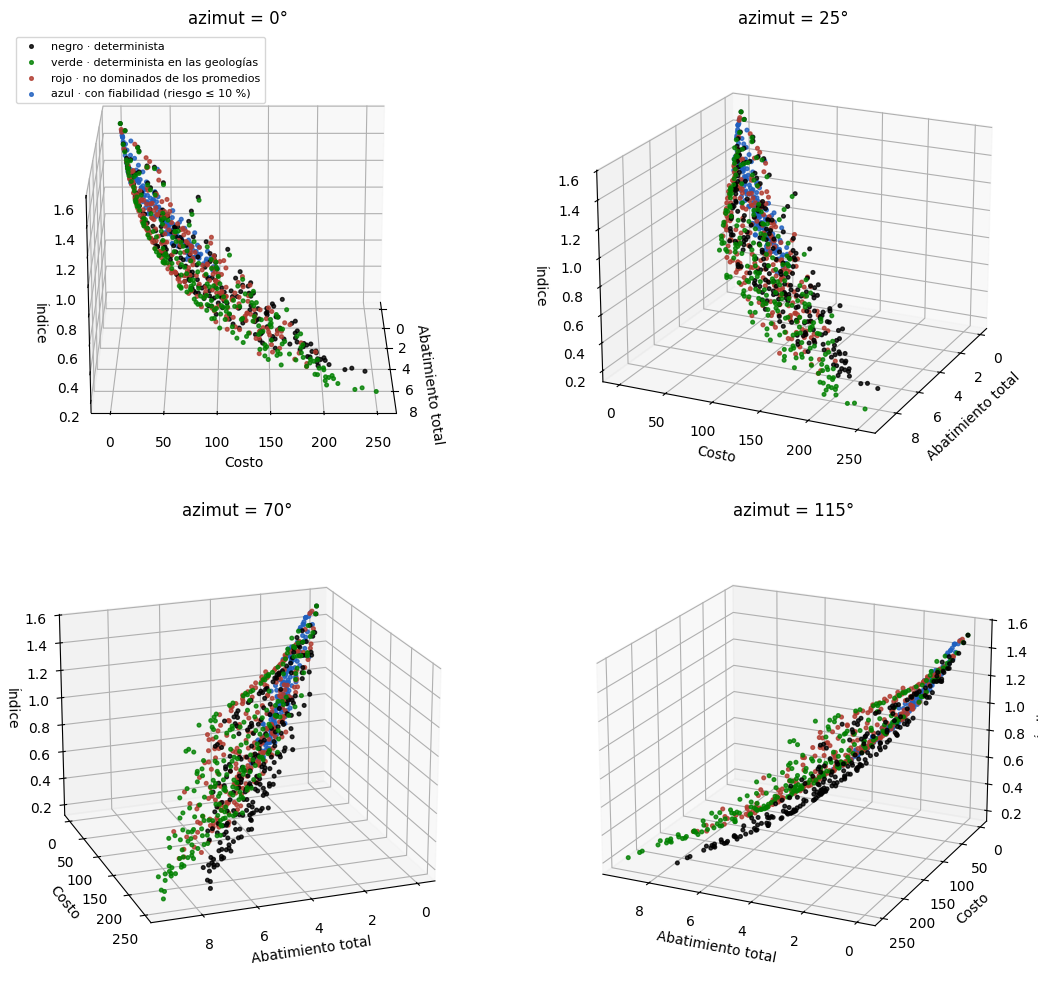

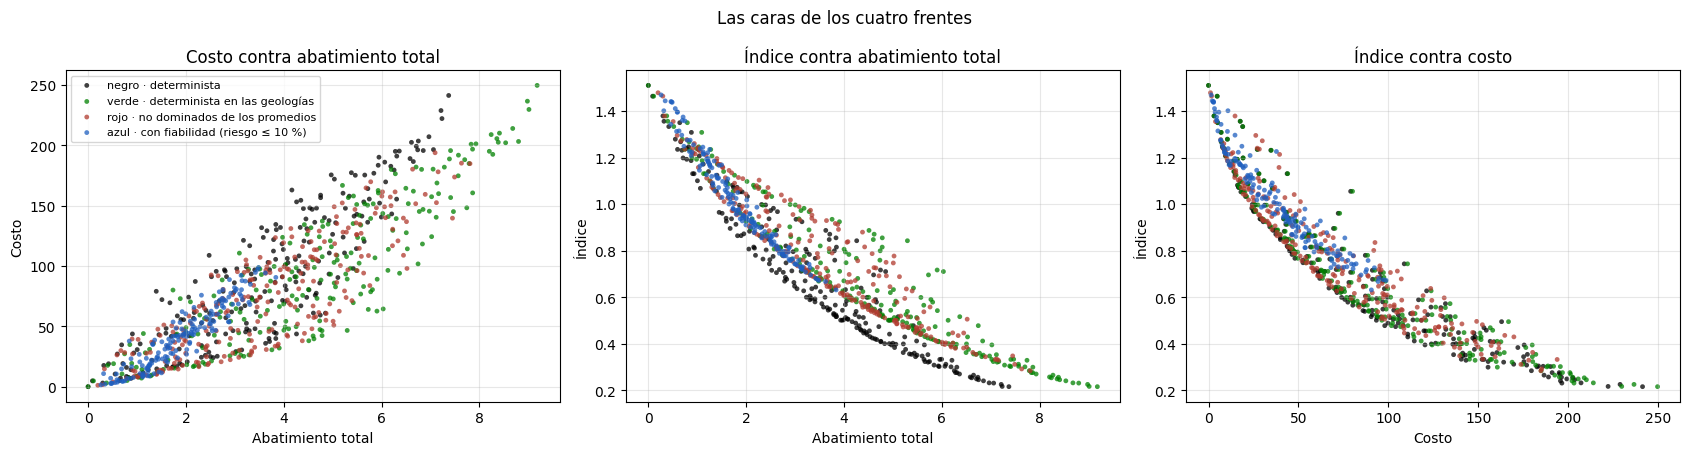

frente                                   soluciones  bombeo total [m³/d] índice mín   riesgo en validación
negro y verde (las mismas decisiones)           216         0 a   809         0.215     media   25%, máxima   72%
rojo                                            240        18 a   686         0.284     media   16%, máxima   56%
azul                                            160        24 a   336         0.631     media    2%, máxima   10%


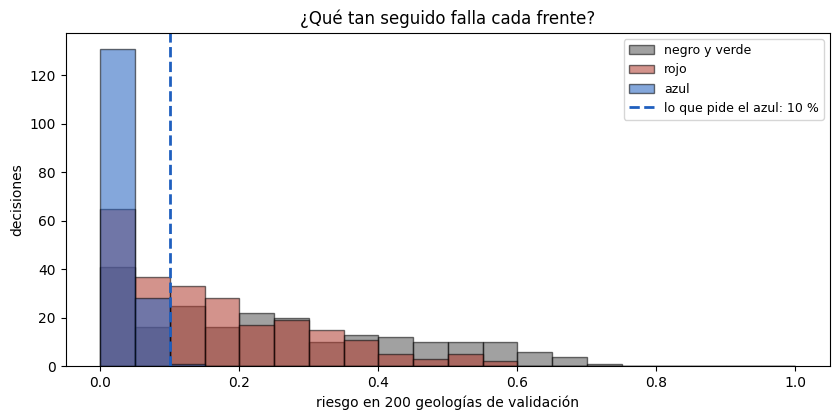

In [20]:
def promedios(x):
    # E[S], E[costo] e I de la decisión x sobre las 200 geologías (sin castigo)
    s_sim = A @ x
    return np.array([s_sim.sum(axis=1).mean(), np.sum(C_QP * x * (GSLEV - H0 + s_sim), axis=1).mean(), np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * x)))])

frentes = {'negro · determinista': (det, 'black'), 'verde · determinista en las geologías': (Het_mat, 'green'),
           'rojo · no dominados de los promedios': (np.array([promedios(x) for x in X_rojo]), '#B03A2E'),
           'azul · con fiabilidad (riesgo ≤ 10 %)': (np.array([promedios(x) for x in X_azul]), '#1f5fbf')}

# Distintos ángulos de azimut que queremos usar
azimuts = [0, 25, 70, 115]
elevacion = 20
fig = plt.figure(figsize=(12, 10))
for i, azim in enumerate(azimuts):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')
    for nombre, (F, color) in frentes.items():
        ax.scatter3D(F[:, 0], F[:, 1], F[:, 2], color=color, s=7, alpha=0.8, label=nombre)
    ax.view_init(elev=elevacion, azim=azim)
    ax.set_xlabel('Abatimiento total'); ax.set_ylabel('Costo'); ax.set_zlabel('Índice'); ax.set_title(f'azimut = {azim}°')
    if i == 0:
        ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

# Los mismos cuatro frentes en una figura que se gira con el mouse (hidra.frente_3d usa plotly)
fig = hidra.frente_3d(*[(F, nombre, color) for nombre, (F, color) in frentes.items()],
                      ejes=('Abatimiento total', 'Costo', 'Índice'), titulo='Los cuatro frentes: negro, verde, rojo y azul', alto=650)
fig.show()

# Las tres caras de los cuatro frentes, en 2-D
hidra.caras_frente(*[(F, nombre, color) for nombre, (F, color) in frentes.items()],
                   ejes=('Abatimiento total', 'Costo', 'Índice'), titulo='Las caras de los cuatro frentes')
plt.show()

print(f"{'frente':40s} {'soluciones':>10s} {'bombeo total [m³/d]':>20s} {'índice mín':>10s}   riesgo en validación")
tabla_frentes = {}
for nombre, X in (('negro y verde (las mismas decisiones)', X_negro), ('rojo', X_rojo), ('azul', X_azul)):
    r_val = np.array([riesgo(x, A_val, H_val) for x in X]); I_min = min(promedios(x)[2] for x in X)
    tabla_frentes[nombre] = (len(X), X.sum(1).min(), X.sum(1).max(), I_min, r_val.mean(), r_val.max())
    print(f"{nombre:40s} {len(X):10d} {X.sum(1).min():9.0f} a {X.sum(1).max():5.0f} {I_min:13.3f}     media {r_val.mean():5.0%}, máxima {r_val.max():5.0%}")

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for nombre, X, color in (('negro y verde', X_negro, '#555555'), ('rojo', X_rojo, '#B03A2E'), ('azul', X_azul, '#1f5fbf')):
    ax.hist([riesgo(x, A_val, H_val) for x in X], bins=np.linspace(0, 1, 21), color=color, alpha=0.55, label=nombre, edgecolor='k')
ax.axvline(RIESGO_MAX, color='#1f5fbf', ls='--', lw=2, label='lo que pide el azul: 10 %')
ax.set_xlabel('riesgo en 200 geologías de validación'); ax.set_ylabel('decisiones'); ax.legend(fontsize=9)
ax.set_title('¿Qué tan seguido falla cada frente?'); plt.tight_layout(); plt.show()

Lo que muestran los cuatro frentes:

- **Negro → verde:** la incertidumbre geológica corre el frente: en promedio, las mismas decisiones abaten más (el costo apenas cambia).
- **En las caras** se ve dónde queda cada frente: el azul ocupa solo el tramo de poco abatimiento y poco costo, con el índice alto (mucha necesidad sin cubrir).
- **Rojo:** optimizar con los promedios da un frente propio, pero exigir las reglas «en promedio» deja decisiones que fallan en buena parte de las geologías.
- **Azul:** exigir fiabilidad cumple la promesa en geologías nuevas (alrededor del 10 % pedido; alguna puede salir un punto arriba por el error de Monte Carlo). Y el
  menú **se encoge**: desaparecen las decisiones que más bombean y el índice ya no baja tanto. Ese pedazo que falta de la cinta es el **costo de la robustez**.

✏️ **Inténtalo:** cambia `RIESGO_MAX` a 0.05 o a 0.20 y vuelve a correr 2.5 y 2.6. ¿Cuánto cambia el menú?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · AGUA CONTRA RIESGO · PRÁCTICA 4.1 Y 4.2</p>

## 3 · Agua contra riesgo: el riesgo como objetivo (18 min)

**La pregunta de Fritz:** ¿cuánta agua puedo bombear, y con qué riesgo?

Un problema distinto del de la sección 2: dos objetivos, el agua y el riesgo, y los tres pozos de 0 a 400 m³/d.

### 3.1 El óptimo de la sesión 1 en 200 geologías

La decisión óptima de la sesión 1 (370.88, 136.46 y 300 m³/d: 807.34 en total, con certificado), evaluada en las 200 geologías. El **riesgo** de una decisión es la
probabilidad de que rompa alguna regla: una **esperanza**, como en la sección 1,

$$
\text{riesgo}(\mathbf{p}) = E\big[\mathbb{1}\{\mathbf{p} \text{ falla}\}\big] \;\approx\; \frac{1}{N}\sum_{k=1}^{N} \mathbb{1}\{\mathbf{p} \text{ falla en la geología } k\}
$$

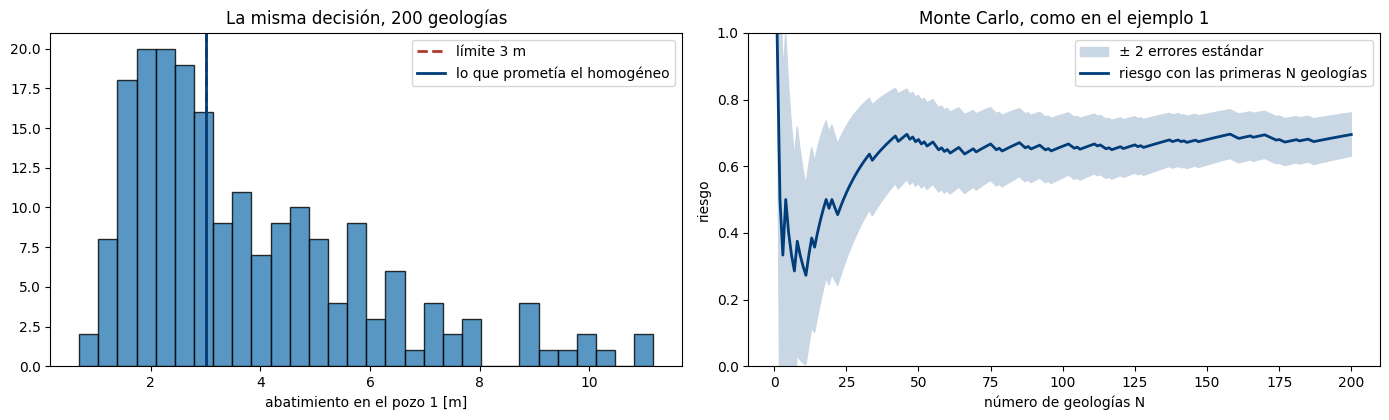

la decisión de la sesión 1 rompe alguna regla en 70% de las geologías


In [21]:
p_s1 = np.array([370.88, 136.46, 300.0])
falla_s1 = ((A @ p_s1) > S_MAX + 1e-9).any(axis=1) | ((H @ p_s1) > S_HUM + 1e-9)
N = np.arange(1, 201); r_acum = np.cumsum(falla_s1) / N; error = np.sqrt(r_acum * (1 - r_acum) / N)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3))
ax1.hist((A @ p_s1)[:, 0], bins=30, color="#2E7DB5", edgecolor="k", alpha=0.8); ax1.axvline(3, color="#B03A2E", ls="--", lw=2, label="límite 3 m")
ax1.axvline(alpha0[0] @ p_s1, color="#003D79", lw=2, label="lo que prometía el homogéneo"); ax1.set_xlabel("abatimiento en el pozo 1 [m]"); ax1.legend()
ax1.set_title("La misma decisión, 200 geologías")
ax2.fill_between(N, r_acum - 2 * error, r_acum + 2 * error, color="#c9d6e4", label="± 2 errores estándar")
ax2.plot(N, r_acum, color="#003D79", lw=2, label="riesgo con las primeras N geologías"); ax2.set_ylim(0, 1)
ax2.set_xlabel("número de geologías N"); ax2.set_ylabel("riesgo"); ax2.legend(); ax2.set_title("Monte Carlo, como en el ejemplo 1")
plt.tight_layout(); plt.show()
print(f"la decisión de la sesión 1 rompe alguna regla en {falla_s1.mean():.0%} de las geologías")

La decisión «óptima con certificado» falla en **siete de cada diez** geologías. El certificado era verdadero, pero para un acuífero que no existe: el homogéneo.

### 3.2 El problema robusto

La pregunta ya no es «¿cuánto puedo bombear?», sino **«¿cuánta agua puedo bombear con qué riesgo?»**:

$$
\min_{\mathbf{p}}\;\Big(\;\underbrace{1200 - (p_1 + p_2 + p_3)}_{\text{déficit de agua}}\;,\;\underbrace{E\big[\mathbb{1}\{\mathbf{p}\text{ falla}\}\big]}_{\text{riesgo}}\;\Big), \qquad 0 \le p_i \le 400
$$

- El riesgo es la «optimización robusta basada en valores esperados» del programa, aplicada a la falla.
- Los **tres** bombeos se deciden: renegociar el contrato del pozo 3 es parte de la respuesta.
- `linprog` ya no sirve: el riesgo cambia a saltos. Es trabajo para OMOPSO.

### 3.3 El frente exacto y OMOPSO robusto

Con tres variables podemos evaluar una malla (cada 10 m³/d) en las 200 geologías y quedarnos, para cada nivel de riesgo, con la decisión que más agua da.

In [22]:
g = np.arange(0, 401, 10.0)
MALLA = np.array(np.meshgrid(g, g, g, indexing="ij")).reshape(3, -1).T        # 68 921 decisiones
Z_MALLA = MALLA.sum(axis=1)

def fallas_malla(A, H, lim_pozo=None, lim_hum=None, perdidas=None):
    # (decisiones, geologías): ¿rompe alguna regla cada decisión en cada geología? Los límites pueden cambiar por geología (sección 4)
    n = len(A)
    lim_pozo = np.full(n, S_MAX) if lim_pozo is None else lim_pozo
    lim_hum = np.full(n, S_HUM) if lim_hum is None else lim_hum
    F = np.zeros((len(MALLA), n), dtype=bool)
    for k in range(n):
        s = MALLA @ A[k].T
        if perdidas is not None:
            s = s + perdidas[k] * MALLA**2
        F[:, k] = (s > lim_pozo[k] + 1e-9).any(axis=1) | ((MALLA @ H[k]) > lim_hum[k] + 1e-9)
    return F

def frente_riesgo(R):
    # para cada nivel de riesgo, la decisión de la malla con más agua: el frente exacto (déficit, riesgo, índice en la malla)
    filas = []
    for r in np.unique(R):
        ok = R <= r + 1e-12; i = np.flatnonzero(ok)[np.argmax(Z_MALLA[ok])]
        if not filas or DEMANDA - Z_MALLA[i] < filas[-1][0] - 1e-9:
            filas.append([DEMANDA - Z_MALLA[i], R[i], i])
    return np.array(filas)

def agua_con_riesgo(FR, r):
    # el máximo bombeo del frente con riesgo ≤ r
    return DEMANDA - FR[FR[:, 1] <= r + 1e-12][-1][0]

t0 = time.time()
FALLAS = fallas_malla(A, H); R_opt = FALLAS.mean(axis=1)
FR = frente_riesgo(R_opt)
print(f"frente exacto con 200 geologías: {len(FR)} puntos, en {time.time() - t0:.1f} s")
for r in (0.0, 0.05, 0.10, 0.20, 0.30):
    print(f"  riesgo ≤ {r:.0%}: hasta {agua_con_riesgo(FR, r):.0f} m³/d")

frente exacto con 200 geologías: 92 puntos, en 0.2 s
  riesgo ≤ 0%: hasta 190 m³/d
  riesgo ≤ 5%: hasta 290 m³/d
  riesgo ≤ 10%: hasta 350 m³/d
  riesgo ≤ 20%: hasta 430 m³/d
  riesgo ≤ 30%: hasta 500 m³/d


#### OMOPSO robusto

Si el modelo no fuera lineal no habría malla: se optimiza directamente. La función objetivo robusta evalúa la decisión en las 200 geologías (Monte Carlo **dentro** del
optimizador, con muestras comunes como en el ejemplo 5) y devuelve el déficit y el riesgo.

OMOPSO robusto: 89 soluciones en 7 s; agua que le falta frente al exacto: media 15.2 m³/d


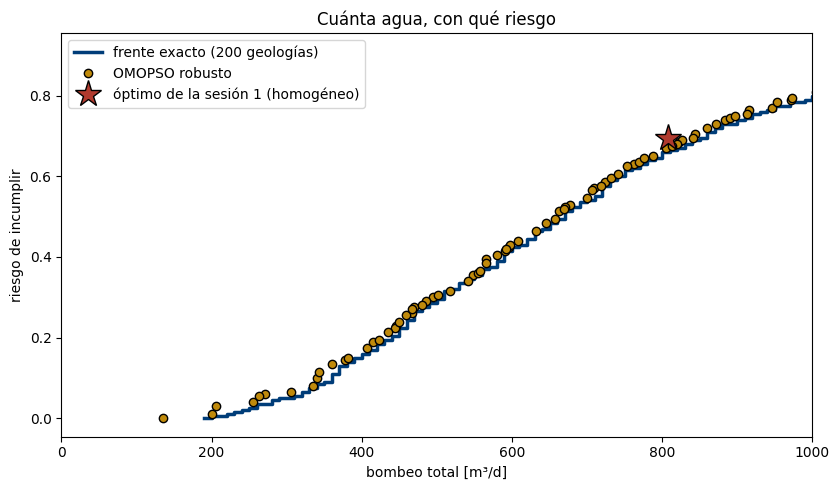

In [23]:
def objetivos_robustos(q):
    x = np.asarray(q, dtype=float)
    return np.array([[DEMANDA - x.sum(), riesgo(x)]]).T       # columna: [déficit, riesgo]

# Esta celda tarda unos 30 segundos
np.random.seed(2026); t0 = time.time()
e_rob, _, _ = parOMOPSO({'CostFunction': objetivos_robustos, 'nVar': 3, 'VarMin': 0, 'VarMax': 400}, dict(OMOPSO, MaxIter=100, nPop=40))
F_omo, X_omo = frente(e_rob)
falta = [F_omo[F_omo[:, 1] <= r + 1e-12, 0].min() - d for d, r, _ in FR if (F_omo[:, 1] <= r + 1e-12).any()]
print(f"OMOPSO robusto: {len(F_omo)} soluciones en {time.time() - t0:.0f} s; agua que le falta frente al exacto: media {np.mean(falta):.1f} m³/d")
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.step(DEMANDA - FR[:, 0], FR[:, 1], where="post", color="#003D79", lw=2.5, label="frente exacto (200 geologías)")
ax.plot(DEMANDA - F_omo[:, 0], F_omo[:, 1], "o", mfc="#C08A0B", mec="k", ms=6, label="OMOPSO robusto")
ax.plot(807.34, falla_s1.mean(), "*", ms=20, mfc="#B03A2E", mec="k", label="óptimo de la sesión 1 (homogéneo)")
ax.set_xlabel("bombeo total [m³/d]"); ax.set_ylabel("riesgo de incumplir"); ax.set_xlim(0, 1000); ax.legend()
ax.set_title("Cuánta agua, con qué riesgo"); plt.tight_layout(); plt.show()

La curva es el **menú robusto**. Arriba a la derecha está la decisión de la sesión 1: mucha agua, riesgo de 70 %. Cumplir en todas las geologías solo permite unos
190 m³/d. La decisión ya no se puede tomar sin decir cuánto riesgo se acepta.

### 3.4 La prueba de fuego: validación y cuántas geologías hacen falta

In [24]:
FALLAS_VAL = fallas_malla(A_val, H_val); R_val = FALLAS_VAL.mean(axis=1)
print("riesgo prometido   bombeo    riesgo real (200 geologías nuevas)")
for r in (0.0, 0.05, 0.10, 0.20):
    i = int(FR[FR[:, 1] <= r + 1e-12][-1][2])
    print(f"      {r:5.0%}        {Z_MALLA[i]:6.0f}        {R_val[i]:6.1%}")

riesgo prometido   bombeo    riesgo real (200 geologías nuevas)
         0%           190          2.5%
         5%           290          5.5%
        10%           350         10.5%
        20%           430         21.5%


#### ¿Cuántas geologías hacen falta?

El ejemplo 6, en el acuífero: optimizamos con las primeras N geologías y validamos siempre en las 200 nuevas.

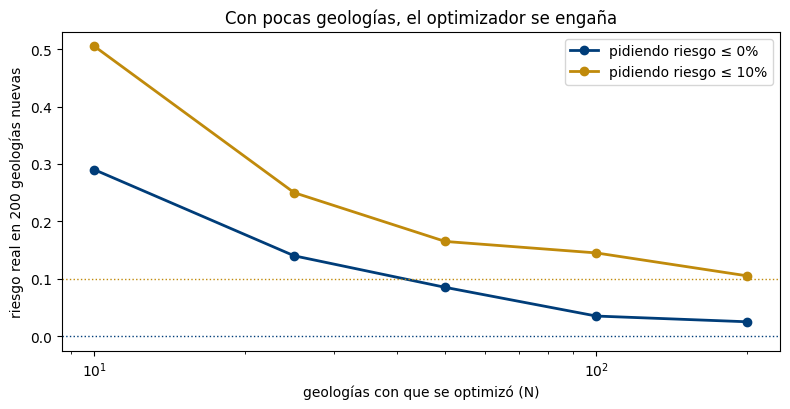

N =  10, pidiendo 0%:  430 m³/d, riesgo real 29.0%
N =  10, pidiendo 10%:  600 m³/d, riesgo real 50.5%
N =  25, pidiendo 0%:  360 m³/d, riesgo real 14.0%
N =  25, pidiendo 10%:  450 m³/d, riesgo real 25.0%
N =  50, pidiendo 0%:  280 m³/d, riesgo real 8.5%
N =  50, pidiendo 10%:  370 m³/d, riesgo real 16.5%
N = 100, pidiendo 0%:  220 m³/d, riesgo real 3.5%
N = 100, pidiendo 10%:  380 m³/d, riesgo real 14.5%
N = 200, pidiendo 0%:  190 m³/d, riesgo real 2.5%
N = 200, pidiendo 10%:  350 m³/d, riesgo real 10.5%


In [25]:
filas = []
for n in sorted({m for m in (10, 25, 50, 100, 200, 500, 1000, 2000, 5000) if m < len(A)} | {len(A)}):
    Fn = frente_riesgo(FALLAS[:, :n].mean(axis=1))
    for r in (0.0, 0.10):
        i = int(Fn[Fn[:, 1] <= r + 1e-12][-1][2])
        filas.append((n, r, Z_MALLA[i], R_val[i]))
fig, ax = plt.subplots(figsize=(8, 4.2))
for r, c in ((0.0, "#003D79"), (0.10, "#C08A0B")):
    xs_n = [f_[0] for f_ in filas if f_[1] == r]; ys = [f_[3] for f_ in filas if f_[1] == r]
    ax.plot(xs_n, ys, "o-", color=c, lw=2, label=f"pidiendo riesgo ≤ {r:.0%}"); ax.axhline(r, color=c, ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("geologías con que se optimizó (N)"); ax.set_ylabel("riesgo real en 200 geologías nuevas"); ax.legend()
ax.set_title("Con pocas geologías, el optimizador se engaña"); plt.tight_layout(); plt.show()
for n, r, z, rv in filas:
    print(f"N = {n:3d}, pidiendo {r:.0%}: {z:4.0f} m³/d, riesgo real {rv:.1%}")

Con diez geologías el optimizador promete riesgo cero y en la realidad falla en casi tres de cada diez casos: la **maldición del optimizador**.

### 3.5 La decisión de Fritz

Fritz acepta, como mucho, un **5 % de riesgo**:

decisión robusta: p = [ 90.  70. 130.] -> 290 m³/d, riesgo 5.0% en las 200 de optimización y 5.5% en las 200 nuevas
comparada con la sesión 1: 517 m³/d menos de agua, y el riesgo baja de 70% a 6%


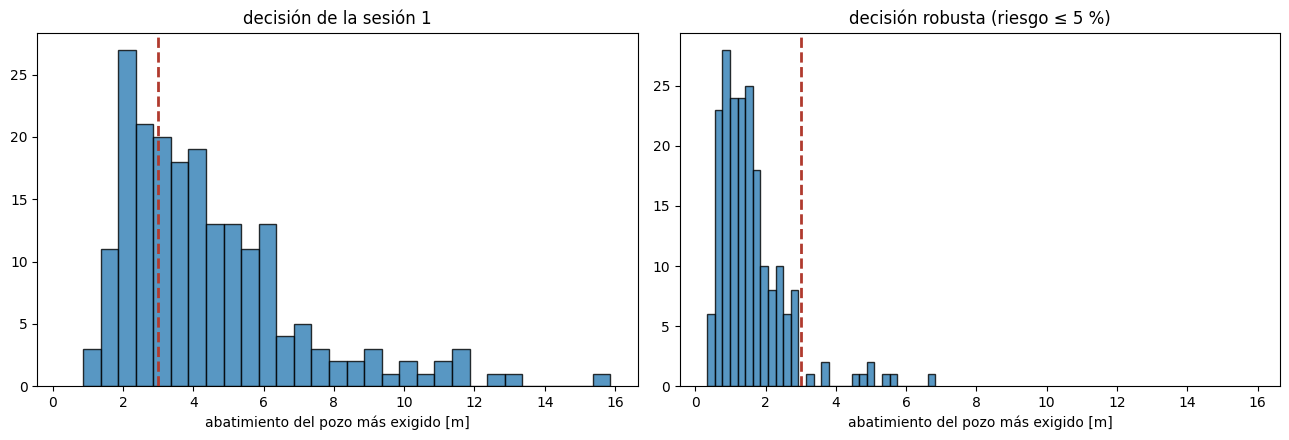

In [26]:
i_rob = int(FR[FR[:, 1] <= 0.05 + 1e-12][-1][2]); p_rob = MALLA[i_rob]
print(f"decisión robusta: p = {p_rob} -> {Z_MALLA[i_rob]:.0f} m³/d, riesgo {R_opt[i_rob]:.1%} en las 200 de optimización y {R_val[i_rob]:.1%} en las 200 nuevas")
print(f"comparada con la sesión 1: {807.34 - Z_MALLA[i_rob]:.0f} m³/d menos de agua, y el riesgo baja de {falla_s1.mean():.0%} a {R_val[i_rob]:.0%}")
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, (x, titulo) in zip(ejes, ((p_s1, "decisión de la sesión 1"), (p_rob, "decisión robusta (riesgo ≤ 5 %)"))):
    ax.hist((A @ x).max(axis=1), bins=30, color="#2E7DB5", edgecolor="k", alpha=0.8); ax.axvline(3, color="#B03A2E", ls="--", lw=2)
    ax.set_xlabel("abatimiento del pozo más exigido [m]"); ax.set_title(titulo)
plt.tight_layout(); plt.show()

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · EL COSTO DE LA ROBUSTEZ Y CÓMO BAJARLO · PRÁCTICA 4.2</p>

## 4 · El costo de la robustez y cómo bajarlo (10 min)

**La pregunta de Fritz:** ¿cuánto me cuesta no saber, y qué hago al respecto?

Primero el **costo** en agua de cada incertidumbre (4.1 y 4.2); después, dos maneras de abaratar la robustez: **medir** (4.3) y **reducir el cómputo** (4.4, para casa).


La geología no es lo único que Fritz no controla. Hasta aquí las reglas eran fijas: 3 m en los pozos y 1.25 m en el humedal. Pero el acuífero tiene **estaciones**:

- En **estiaje** el nivel estático baja hasta $\delta = 0.8$ m. La bomba está a la misma profundidad, así que el abatimiento disponible en los pozos es $3 - \delta$.
- En estiaje el humedal está más seco y **tolera menos**: el límite baja de 1.25 m a 1.05 m.

No sabemos en qué mes ocurrirá la peor geología: el clima es **otra incertidumbre**. Como contraste, una tercera fuente: las **pérdidas de pozo** (eficiencia de
la bomba, incrustación), un abatimiento extra $C_i\,p_i^2$ con $C_i$ incierto (unos 0.4 m a 300 m³/d).

### 4.1 El costo en agua: geología y clima

Cada geología del ensamble se acompaña de un mes al azar y de unas pérdidas al azar. El riesgo sigue siendo la fracción de casos en que la decisión falla.

In [27]:
rng_c = np.random.default_rng(7)
mes = rng_c.integers(0, 12, len(A))                                   # el mes de cada caso (0 = el más seco)
estiaje = 0.5 * (1 + np.cos(2 * np.pi * mes / 12))                   # 1 en el mes más seco, 0 en el más húmedo
delta = 0.8 * estiaje                                                 # cuánto baja el nivel estático [m]
lim_pozo_clima = S_MAX - delta                                        # abatimiento disponible en los pozos
lim_hum_clima = S_HUM - 0.20 * estiaje                                # tolerancia del humedal
C_perdidas = rng_c.lognormal(np.log(4.4e-6), 0.5, (len(A), 3))        # pérdidas de pozo: s extra = C p²

fuentes = {
    "geología": FALLAS,
    "geología + clima": fallas_malla(A, H, lim_pozo=lim_pozo_clima, lim_hum=lim_hum_clima),
    "geología + pérdidas de pozo": fallas_malla(A, H, perdidas=C_perdidas),
    "geología + clima + pérdidas": fallas_malla(A, H, lim_pozo=lim_pozo_clima, lim_hum=lim_hum_clima, perdidas=C_perdidas),
}
frentes_fuente = {nombre: frente_riesgo(F.mean(axis=1)) for nombre, F in fuentes.items()}
print("agua máxima [m³/d] con riesgo aceptado")
print(f"{'':30s}" + "".join(f"{r:>8.0%}" for r in (0.0, 0.05, 0.10, 0.20)))
print(f"{'determinista (homogéneo)':30s}" + "".join(f"{807:>8d}" for _ in range(4)))
for nombre, Fq in frentes_fuente.items():
    print(f"{nombre:30s}" + "".join(f"{agua_con_riesgo(Fq, r):>8.0f}" for r in (0.0, 0.05, 0.10, 0.20)))

agua máxima [m³/d] con riesgo aceptado
                                    0%      5%     10%     20%
determinista (homogéneo)           807     807     807     807
geología                           190     290     350     430
geología + clima                   150     240     300     360
geología + pérdidas de pozo        190     290     350     420
geología + clima + pérdidas        150     240     290     350


#### La escalera del costo

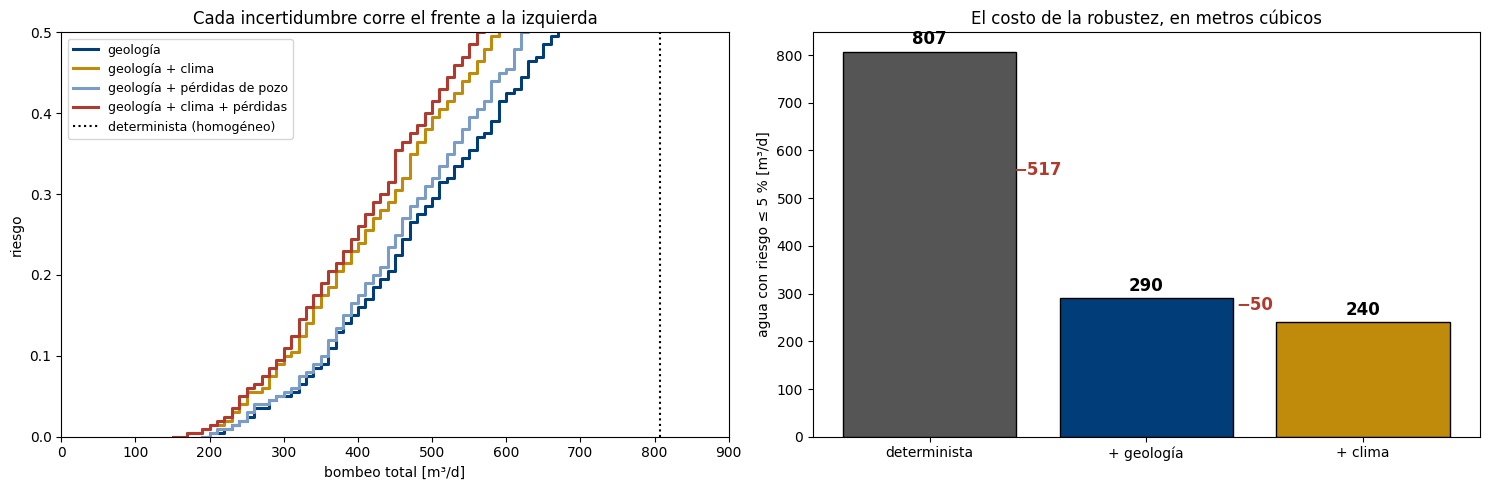

In [28]:
colores = {"geología": "#003D79", "geología + clima": "#C08A0B", "geología + pérdidas de pozo": "#7a9cc6", "geología + clima + pérdidas": "#B03A2E"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for nombre, Fq in frentes_fuente.items():
    ax1.step(DEMANDA - Fq[:, 0], Fq[:, 1], where="post", lw=2.2, color=colores[nombre], label=nombre)
ax1.axvline(807.34, color="k", ls=":", label="determinista (homogéneo)")
ax1.set_xlabel("bombeo total [m³/d]"); ax1.set_ylabel("riesgo"); ax1.set_xlim(0, 900); ax1.set_ylim(0, 0.5); ax1.legend(fontsize=9)
ax1.set_title("Cada incertidumbre corre el frente a la izquierda")
escalones = [("determinista", 807.34), ("+ geología", agua_con_riesgo(frentes_fuente["geología"], 0.05)),
             ("+ clima", agua_con_riesgo(frentes_fuente["geología + clima"], 0.05))]
ax2.bar([e[0] for e in escalones], [e[1] for e in escalones], color=["#555555", "#003D79", "#C08A0B"], edgecolor="k")
for k, (nombre, z) in enumerate(escalones):
    ax2.text(k, z + 15, f"{z:.0f}", ha="center", fontsize=12, fontweight="bold")
    if k:
        ax2.annotate(f"−{escalones[k - 1][1] - z:.0f}", (k - 0.5, (escalones[k - 1][1] + z) / 2), ha="center", color="#B03A2E", fontsize=12, fontweight="bold")
ax2.set_ylabel("agua con riesgo ≤ 5 % [m³/d]"); ax2.set_title("El costo de la robustez, en metros cúbicos")
plt.tight_layout(); plt.show()

- La **geología** es, por mucho, la incertidumbre más cara: de 807 a menos de 300 m³/d con 5 % de riesgo.
- El **clima** cuesta otros ~50 m³/d.
- Las **pérdidas de pozo** casi no cuestan: con bombeos tan bajos, $C\,p^2$ es pequeño. No toda incertidumbre merece modelarse: hay que **medir** cuál importa.

### 4.2 La incertidumbre que se ignora

¿Qué pasa si optimizamos solo con la geología y el clima existe?

In [29]:
i_geo = int(frentes_fuente["geología"][frentes_fuente["geología"][:, 1] <= 0.05 + 1e-12][-1][2])
print(f"decisión robusta a la geología (riesgo prometido 5 %): p = {MALLA[i_geo]}, {Z_MALLA[i_geo]:.0f} m³/d")
for nombre, Fm in fuentes.items():
    print(f"   riesgo real con {nombre:28s}: {Fm[i_geo].mean():.1%}")

decisión robusta a la geología (riesgo prometido 5 %): p = [ 90.  70. 130.], 290 m³/d
   riesgo real con geología                    : 5.0%
   riesgo real con geología + clima            : 10.5%
   riesgo real con geología + pérdidas de pozo : 5.5%
   riesgo real con geología + clima + pérdidas : 11.5%


Cada incertidumbre que se ignora se convierte en **riesgo que no se ve**: la decisión prometía 5 % y con el clima falla el doble. Cada incertidumbre que se incluye
**cuesta agua**. Ese es el costo de la robustez, y es honesto pagarlo.

### 4.3 Bajar el costo midiendo: una prueba de bombeo

El costo de la robustez viene de **no saber**. Una **prueba de bombeo** en el pozo 1 mide cuánto abaten los tres pozos y el humedal: una columna de la matriz de la
geología real. Nos quedamos con las 80 geologías del ensamble que más se parecen a lo medido y con ellas se vuelve a optimizar. Con 80 en lugar de 200 la maldición
del optimizador acecha (ejemplo 6), así que se pide un poco menos de riesgo (2.5 %) para que la falla **real** sea la misma que sin la prueba.

Lo probamos con las 200 geologías del ensamble de validación, cada una haciendo de «geología real»:

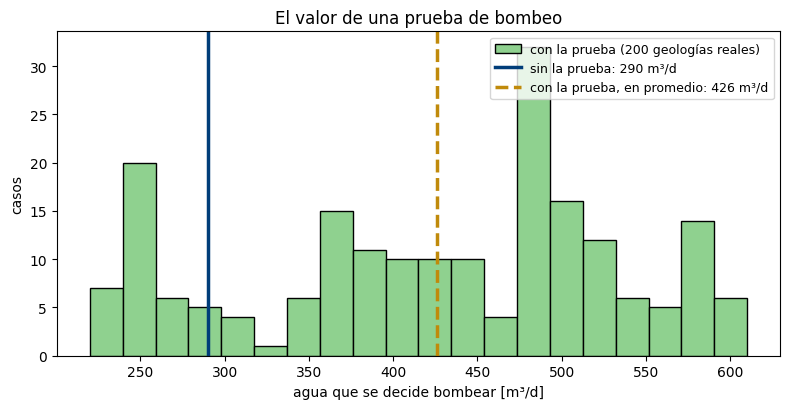

sin prueba: 290 m³/d, falla real 5.5%
con prueba: 426 m³/d en promedio (de 220 a 610), falla real 5.5%


In [30]:
obs_ens = np.column_stack([A[:, :, 0], H[:, 0]])                       # lo que mediría la prueba en cada geología del ensamble
escala_obs = obs_ens.std(axis=0)
agua_post, falla_post = [], []
for v in range(len(A_val)):
    obs = np.append(A_val[v][:, 0], H_val[v][0])                       # lo que mide la prueba en la geología «real» v
    cercanas = np.argsort(np.linalg.norm((obs_ens - obs) / escala_obs, axis=1))[:80]
    r_post = FALLAS[:, cercanas].mean(axis=1); ok = r_post <= 0.025 + 1e-12
    i = np.flatnonzero(ok)[np.argmax(Z_MALLA[ok])]
    agua_post.append(Z_MALLA[i]); falla_post.append(FALLAS_VAL[i, v])
agua_post = np.array(agua_post)
z_prior = agua_con_riesgo(FR, 0.05)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(agua_post, bins=20, color="#8fd18f", edgecolor="k", label="con la prueba (200 geologías reales)")
ax.axvline(z_prior, color="#003D79", lw=2.5, label=f"sin la prueba: {z_prior:.0f} m³/d")
ax.axvline(agua_post.mean(), color="#C08A0B", lw=2.5, ls="--", label=f"con la prueba, en promedio: {agua_post.mean():.0f} m³/d")
ax.set_xlabel("agua que se decide bombear [m³/d]"); ax.set_ylabel("casos"); ax.legend(fontsize=9)
ax.set_title("El valor de una prueba de bombeo"); plt.tight_layout(); plt.show()
print(f"sin prueba: {z_prior:.0f} m³/d, falla real {R_val[int(FR[FR[:, 1] <= 0.05 + 1e-12][-1][2])]:.1%}")
print(f"con prueba: {agua_post.mean():.0f} m³/d en promedio (de {agua_post.min():.0f} a {agua_post.max():.0f}), falla real {np.mean(falla_post):.1%}")

Con la prueba, unas veces Fritz descubre que su acuífero es permisivo y puede bombear mucho más; otras, que es restrictivo y debe bombear menos. **En promedio**
gana agua con el mismo riesgo real: es el **valor de la información**. Antes de optimizar con más cuidado, conviene preguntar qué medición baja más el costo de la robustez.

### 4.4 Bajar el costo de cómputo: OCA (para casa)

*Este apartado es para casa: no se ve en clase ni entra en la Tarea 4. Tarda alrededor de un minuto.*

Cuando cada geología cuesta horas, no se pueden usar 200 dentro del optimizador. La **OCA** (*Optimal Clustering Analysis*, Rodríguez-Pretelín, Nowak y
Morales-Casique, 2022) elige con OMOPSO un subconjunto de k representativas que reproduce un resultado del ensamble completo. Comparamos dos versiones con
subconjuntos de 10 al azar:

- **OCA de mapas** (la del artículo, adaptada): reproducir los isopercentiles 10, 50 y 90 del mapa de «abate más de 1 m» con un bombeo de referencia.
- **OCA orientada al objetivo**: reproducir la curva de riesgo del ensamble para decisiones conservadoras, medias y agresivas.

In [31]:
# Esta celda tarda alrededor de un minuto
N_ENS, K_REP = len(A), 10
p_ref = np.array([250.0, 150.0, 250.0])
mapas = (OPT["alpha_malla"] @ p_ref > 1.0).astype(float)                     # (N, 256): la zona que abate más de 1 m
iso = {t: mapas.mean(axis=0) >= t for t in (0.1, 0.5, 0.9)}
franjas = [(Z_MALLA >= 200) & (Z_MALLA < 450), (Z_MALLA >= 450) & (Z_MALLA < 700), (Z_MALLA >= 700) & (Z_MALLA < 950)]

def error_mapas(S):
    p = mapas[S].mean(axis=0); return np.array([np.sum((p >= t) != iso[t]) for t in (0.1, 0.5, 0.9)], dtype=float)

def error_riesgo(S):
    r = FALLAS[:, S].mean(axis=1); return np.array([np.mean(np.abs(r[f_] - R_opt[f_])) for f_ in franjas])

def oca(error, semilla=1):
    def costo(q):
        S = np.unique(np.minimum(np.floor(q).astype(int), N_ENS - 1))
        if len(S) < K_REP: return np.full((3, 1), 1e3)
        return (error(S) + 1e-3)[:, None]
    np.random.seed(semilla)
    ef, _, _ = parOMOPSO({'CostFunction': costo, 'nVar': K_REP, 'VarMin': 0, 'VarMax': N_ENS - 1e-6}, dict(OMOPSO, MaxIter=60, nPop=40))
    F, _ = frente(ef); Fn = (F - F.min(0)) / np.maximum(F.max(0) - F.min(0), 1e-12)
    return np.unique(np.floor(np.ravel(ef[int(np.argmin(np.linalg.norm(Fn, axis=1)))]['position'])).astype(int))

def riesgo_real(S, r=0.0):
    rs = FALLAS[:, S].mean(axis=1); ok = rs <= r + 1e-12; i = np.flatnonzero(ok)[np.argmax(Z_MALLA[ok])]
    return Z_MALLA[i], R_val[i]

t0 = time.time()
rng_oca = np.random.default_rng(0); azar = np.array([riesgo_real(rng_oca.choice(N_ENS, K_REP, replace=False))[1] for _ in range(100)])
resultados_oca = {nombre: np.array([riesgo_real(oca(error, semilla=s))[1] for s in range(3)])
                  for nombre, error in (("OCA de mapas", error_mapas), ("OCA orientada al objetivo", error_riesgo))}
print(f"6 selecciones de OCA en {time.time() - t0:.0f} s\n")
print("subconjunto de 10              riesgo real pidiendo riesgo 0 (200 geologías nuevas)")
for nombre, rv in resultados_oca.items():
    print(f"{nombre:28s}   media {rv.mean():6.1%}   de {rv.min():.1%} a {rv.max():.1%}   (3 semillas)")
print(f"{'10 al azar':28s}   media {azar.mean():6.1%}   de {np.percentile(azar, 10):.1%} a {np.percentile(azar, 90):.1%}   (100 subconjuntos)")
z, rv = riesgo_real(np.arange(N_ENS))
print(f"{'las 200 geologías':28s}   {rv:6.1%}   (bombeo {z:.0f} m³/d)")

/home/abelardo/UNAM/Curso Corto de optimización/Curso_V3/Session_4/Información/codigo/pyOMOPSO/Sel_Leader.py:34: RuntimeWarning: invalid value encountered in scalar divide
  d[so[i],j] = abs(cj[i+1]-cj[i-1])/abs(cj[0]-cj[-1])


6 selecciones de OCA en 7 s

subconjunto de 10              riesgo real pidiendo riesgo 0 (200 geologías nuevas)
OCA de mapas                   media   9.5%   de 3.5% a 13.5%   (3 semillas)
OCA orientada al objetivo      media  15.5%   de 10.0% a 20.0%   (3 semillas)
10 al azar                     media  19.4%   de 7.0% a 34.1%   (100 subconjuntos)
las 200 geologías                2.5%   (bombeo 190 m³/d)


- En promedio, las dos OCA mejoran al azar, pero el resultado cambia con la semilla: OCA también es estocástica, y se reportan varias corridas.
- **Ninguna** llega a lo que dan las 200 geologías. OCA reduce el costo de cómputo; no quita la necesidad de validar.
- Lo que se le pide reproducir a la selección (mapas o el riesgo de la decisión) es una elección del analista, como la medida de robustez del ejemplo 2.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · CIERRE DEL CURSO</p>

## 5 · Cierre del curso (5 min)

| Sesión | Pregunta | Herramienta | Lo que aprendimos |
|---|---|---|---|
| 1 | ¿Cuánto puede bombear Fritz? | simulador, matriz, `linprog` | si todo es lineal, el óptimo trae certificado |
| 2 | ¿Y sin la matriz? | enjambre de partículas | el optimizador propone y el simulador califica; sin certificado, con estadística |
| 3 | ¿Y si los objetivos se pelean? | OMOPSO, frente de Pareto | la respuesta es un menú; decidir es de las personas |
| 4 | ¿Y si la geología y el clima son otros? | Monte Carlo, riesgo como objetivo, validación, OCA | el óptimo de un modelo no es el del acuífero; la robustez cuesta agua, y medir la abarata |

### Tarea 4

`Tarea_4_estudiante.ipynb`, la misma para todos: la ruta de este cuaderno, desde la función de dos cimas hasta el costo de la robustez con el clima. Es el trabajo
asíncrono de la sesión (unas 2 horas), el último de los cuatro cuadernos de evaluación: entrega el **viernes 27 de noviembre**. Se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado.

### Referencias

- Beyer, H.-G. y Sendhoff, B. (2007). Robust optimization: a comprehensive survey. *Computer Methods in Applied Mechanics and Engineering*, 196(33–34), 3190–3218.
- Deb, K. y Gupta, H. (2006). Introducing robustness in multi-objective optimization. *Evolutionary Computation*, 14(4), 463–494.
- Metropolis, N. y Ulam, S. (1949). The Monte Carlo method. *Journal of the American Statistical Association*, 44(247), 335–341.
- Rodríguez-Pretelín, A., Nowak, W. y Morales-Casique, E. (2022). Optimization-based clustering of random fields for computationally efficient and goal-oriented uncertainty quantification. *Advances in Water Resources*, 162, 104146.
- Rodríguez-Pretelín, A. y Nowak, W. (2018). Integrating transient behavior as a new dimension to WHPA delineation. *Advances in Water Resources*, 119, 178–187.
- Smith, J. E. y Winkler, R. L. (2006). The optimizer's curse: skepticism and postdecision surprise in decision analysis. *Management Science*, 52(3), 311–322.